In [93]:
# We start by importing all the necessary packages
%load_ext autoreload
%autoreload 2
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import torch
from tqdm import tqdm
import math
from Python_files import time_integration_functions as TST
from Python_files import TLM_Test as TT
from Python_files import ETLM as ETLMC
from Python_files import LETLM_ensemble as LETLMC
from Python_files import IETLM_ensemble as IETLMC
from Python_files import GETLM as GETLMC
from Python_files import GETLM_experiment_neat as GEN

from Python_files import GETLM_experiment_neat_IO2 as GENIO
#  We also need to set the precision to be higher as we are working with very small perturbations
torch.set_default_dtype(torch.float64)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [94]:
# we now define stuff as required
model = TST.rk4_L96

N = 40 # The number of grid points
dx = 1 # The spacing
F_L96 = 8 # The Lorenz 96 forcing term
dt = 0.05 # This gives a time step of six hours
timesteps =  14400 # This moves the model forward ten years
alpha = 1 # set for no reason
beta = 1 # set for no reason
model_parameters = (N, dx, dt, alpha, beta, F_L96)

spin_up_time = 1000

perturbation_size = 10**(-7)
ensemble_size = 30
num_steps = 40
trials = 1
LETLM_stencil = [[0], [-9,-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8]]
IETLM_stencil = [[-2,-1,0,1], [-2,-1,0,1]]
GETLM_stencil = [[-2,-1,0,1], [-8,-7,-6,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7],[-2,-1,0,1]]
print(len(GETLM_stencil))

x_values = np.arange(1, num_steps+1)  


3


In [95]:
# We start by defining one trial

# Step 0, set up state vector

# Step 1, spin up the model

# step two: define a test perturbation

# step three iterate through the number of steps

# step 4 generate the TLMs around the current guess field

# step 5: generate the test perturbation

# step 6 do the TLM tests

# step 7 propogate the model forward

# done

In [96]:
# Step 0: 
# we start by initialising the model with a vector of random normal noise
x0 = torch.randn(N)
x_in = [x0, x0.clone()]

# Step 2 
# We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
for i in range(spin_up_time-1):
    # print(x_in[0][0])
    x_in = TST.run_model(x_in, model, model_parameters)
    # print(x_in[0].size())

x_guess = TST.run_model(x_in, model, model_parameters)
# print(x_guess)
# print(x_guess[0].size())


In [97]:
def GETLM_ensemble_generator(x_current, x_past, ensemble_size, standard_deviation,
                             model, model_parameters, number_of_steps=1):
    (N, dx, dt, alpha, beta, F_L96) = model_parameters
    x_current = x_current.reshape(N)
    x_past = x_past.reshape(N)

    X   = torch.randn(N, ensemble_size) * standard_deviation   # past perturbations
    Xi  = torch.randn(N, ensemble_size) * standard_deviation   # current perturbations
    Chi = torch.zeros(N, ensemble_size)                        # future perturbations

    ref = TST.run_model([x_current, x_past], model, model_parameters)   # once, not per member
    for m in range(ensemble_size):
        out = TST.run_model([x_current + Xi[:, m], x_past + X[:, m]], model, model_parameters)
        Chi[:, m] = (out[0] - ref[0]).reshape(N)

    return Chi, Xi, X     # future, current, past perturbations

In [98]:
def TLM_generation_step(x_guess):
    x_current = x_guess[0].squeeze()
    x_past = x_guess[1].squeeze()
    # print(x_current.size())

    # We start by generating the ensemble
    # print('check 1: passed')
    # Chi, Xi, X = GETLMC.GETLM_ensemble_generator(x_current, x_past, ensemble_size, perturbation_size,model,model_parameters, number_of_steps = 1)
    Chi, Xi, X = GETLM_ensemble_generator(x_current, x_past, ensemble_size, perturbation_size,model,model_parameters, number_of_steps = 1)

    # print(Chi)

    # print('check 2: passed')

    #  We can now make the TLMS

    k1 = 1 # number of zero eigenvalue eigenvalues
    k2 = 2 # number of zero eigenvalue eigenvalues
    k3 = 3 # number of zero eigenvalue eigenvalues
    k4 = 4 # number of zero eigenvalue eigenvalues

    # We now make the GETLM
    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, GETLM_stencil, model_parameters, ensemble_size, k1, plot = False)
    GETLM_1 = torch.hstack((torch.pinverse(N_tilde_G) @ L_tilde_G, torch.pinverse(N_tilde_G) @ K_tilde_G))
    # print('Check 3: passed')

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, GETLM_stencil, model_parameters, ensemble_size, k2, plot = False)
    GETLM_2 = torch.hstack((torch.pinverse(N_tilde_G) @ L_tilde_G, torch.pinverse(N_tilde_G) @ K_tilde_G))

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, GETLM_stencil, model_parameters, ensemble_size, k3, plot = False)
    GETLM_3 = torch.hstack((torch.pinverse(N_tilde_G) @ L_tilde_G, torch.pinverse(N_tilde_G) @ K_tilde_G))

    N_tilde_G, L_tilde_G, K_tilde_G = GETLMC.GETLM_generator(Chi, Xi, X, GETLM_stencil, model_parameters, ensemble_size, k4, plot = False)
    GETLM_4 = torch.hstack((torch.pinverse(N_tilde_G) @ L_tilde_G, torch.pinverse(N_tilde_G) @ K_tilde_G))

    # We will now make the IETLM
    N_tilde_I, L_tilde_I = IETLMC.IETLM_generator(Chi, Xi, IETLM_stencil, model_parameters, ensemble_size)
    IETLM = torch.pinverse(N_tilde_I) @ L_tilde_I

    LETLM = LETLMC.LETLM_generator(Chi, Xi, LETLM_stencil, model_parameters, ensemble_size)
    # print('Check 4: passed')

    return LETLM, IETLM, GETLM_1, GETLM_2, GETLM_3, GETLM_4




    



In [99]:
LETLM, IETLM, GETLM_1, GETLM_2, GETLM_3, GETLM_4 = TLM_generation_step(x_guess)

In [100]:
def one_trial():
    x0 = torch.randn(N)
    x_in = [x0, x0.clone()]

    # Step 2 
    # We then run the model so that the Lorenz 96 model has reached it's 'equilibrium'
    for i in range(spin_up_time-1):
        x_in = TST.run_model(x_in, model, model_parameters)
        # print(x_in[0].size())

    x_guess = TST.run_model(x_in, model, model_parameters)




    test_pert_current = torch.randn(N) * perturbation_size
    test_pert_past = torch.randn(N) * perturbation_size
    test_pert = [test_pert_current, test_pert_past]

    x_current = x_guess[0]
    x_past = x_guess[1]
    # print('0')

    # We first define our test perturbation
    test_guess = []
    state_test_pert_current = x_current + test_pert[0]
    state_test_pert = (state_test_pert_current, x_past+test_pert[1])
    # print('1')

    test_guess.append(state_test_pert[0])
    test_guess.append(state_test_pert[1])

    LETLM_pert = test_pert_current
    IETLM_pert = test_pert_current

    GETLM_1_pert = torch.hstack((test_pert_current, test_pert_past))
    GETLM_2_pert = torch.hstack((test_pert_current, test_pert_past))

    # print(GETLM_1_pert.size())

    # x_domain = np.arange(1, N+1)
    # plt.plot(x_domain, LETLM_pert, label ='LETLM', marker = '+')
    # plt.plot(x_domain,IETLM_pert, label = 'IETLM')
    # # plt.plot(x_domain, GETLM_1_pert_future, label = 'GETLM_1')
    # # plt.plot(x_domain, GETLM__pert_future, label = 'GETLM_1')

    # plt.plot(x_domain, test_pert[0], label = 'actual', marker = '*')
    # plt.title('starting states')
    # plt.legend()
    # plt.show()
    # plt.clf()





    LETLM_errors = []
    IETLM_errors = []
    GETLM_1_errors = []
    GETLM_2_errors = []

    
    # step three iterate through the number of steps
    for i in range(num_steps):

        # We start by generating the TLMs around the current guess field
        LETLM, IETLM, GETLM_1, GETLM_2, GETLM_3, GETLM_4 = TLM_generation_step(x_guess)
        # plt.matshow(LETLM)
        # plt.matshow(IETLM)
        # plt.matshow(GETLM_1)
        # plt.matshow(GETLM_4)
        # plt.show()

        test_guess = TST.run_model(test_guess, model, model_parameters)
        # print(x)
        x_guess = TST.run_model(x_guess, model, model_parameters)


        x_test = test_guess[0]
        x_g = x_guess[0]

        LETLM_pert = LETLM @ LETLM_pert
        IETLM_pert = IETLM @ IETLM_pert

        GETLM_1_pert_future = GETLM_1 @ GETLM_1_pert
        current_half = GETLM_1_pert[:N]
        GETLM_1_pert = torch.hstack((GETLM_1_pert_future, current_half))


        # GETLM(2)
        GETLM_2_pert_future = GETLM_2 @ GETLM_2_pert
        current_half = GETLM_2_pert[:N]
        GETLM_2_pert = torch.hstack((GETLM_2_pert_future, current_half))


        x_domain = np.arange(1, N+1)
        plt.plot(x_domain, LETLM_pert, label ='LETLM', marker = '+')
        plt.plot(x_domain,IETLM_pert, label = 'IETLM')
        # plt.plot(x_domain, GETLM_1_pert_future, label = 'GETLM_1')
        plt.plot(x_domain, GETLM_2_pert_future, label = 'GETLM 2', marker = 'd')
        plt.plot(x_domain, x_test - x_g, label = 'actual', marker = '*')
        plt.legend()
        plt.show()
        plt.clf()


        

        # print(x_g.size())
        # print(x_test.size())
        # print(LETLM_pert.size())


        # print("x_test:", x_test.shape)
        # print("x_g:", x_g.shape)
        # print("LETLM_pert:", LETLM_pert.shape)
        # print("LETLM:", LETLM.shape)

        LETLM_result = TT.TLM_test(x_test, x_g, LETLM_pert)
        IETLM_result = TT.TLM_test(x_test, x_g, IETLM_pert)
        GETLM_result_1 = TT.TLM_test(x_test, x_g, GETLM_1_pert_future)
        GETLM_result_2 = TT.TLM_test(x_test, x_g, GETLM_2_pert_future)

        # print(LETLM_result.size())
        LETLM_errors.append(LETLM_result)
        IETLM_errors.append(IETLM_result)
        GETLM_1_errors.append(GETLM_result_1)
        GETLM_2_errors.append(GETLM_result_2)

    return LETLM_errors, IETLM_errors, GETLM_1_errors, GETLM_2_errors




        



  0%|          | 0/1 [00:00<?, ?it/s]

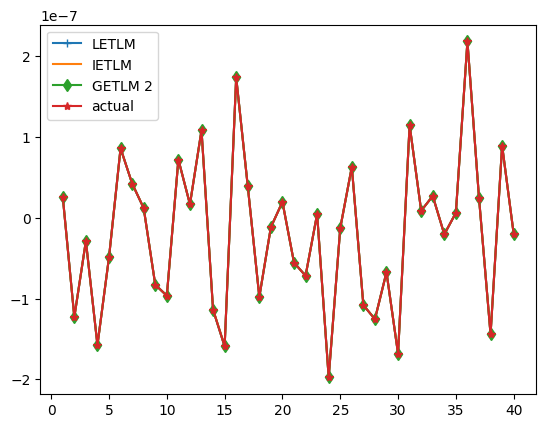

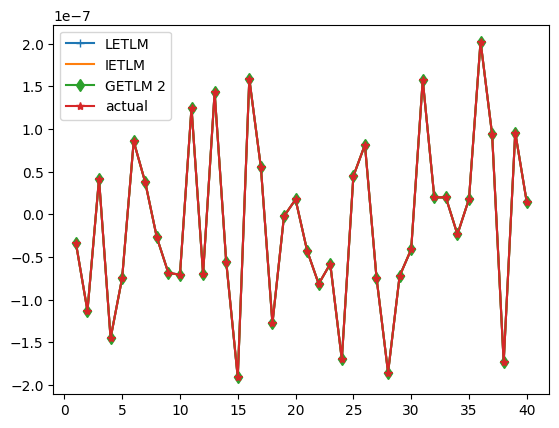

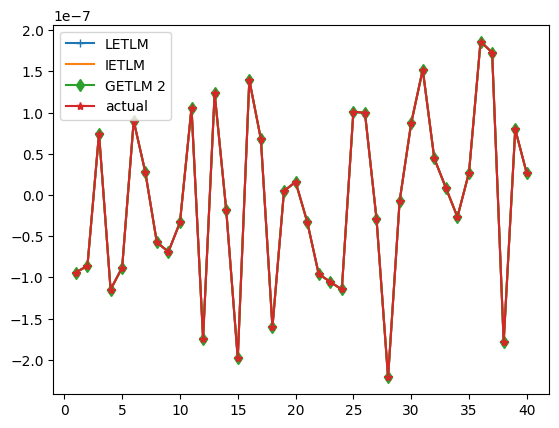

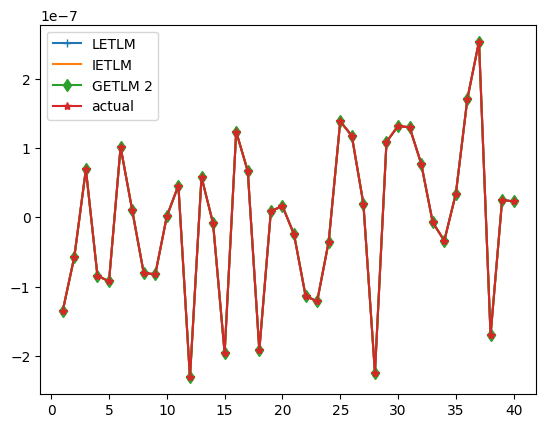

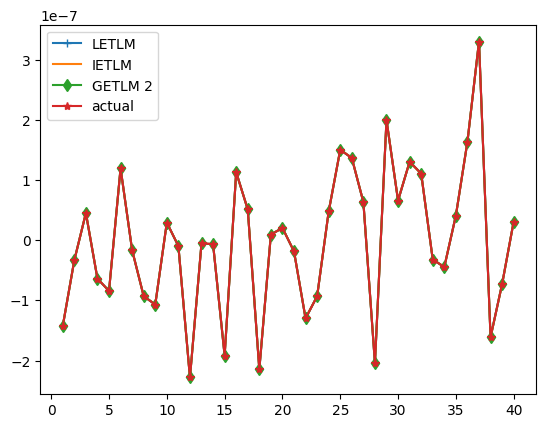

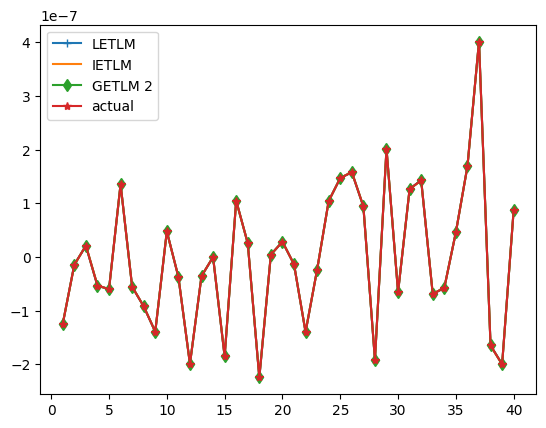

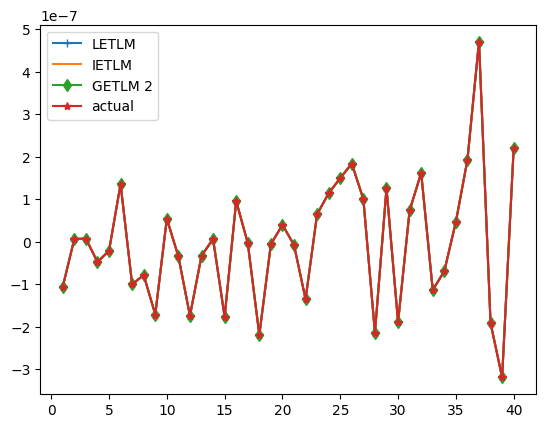

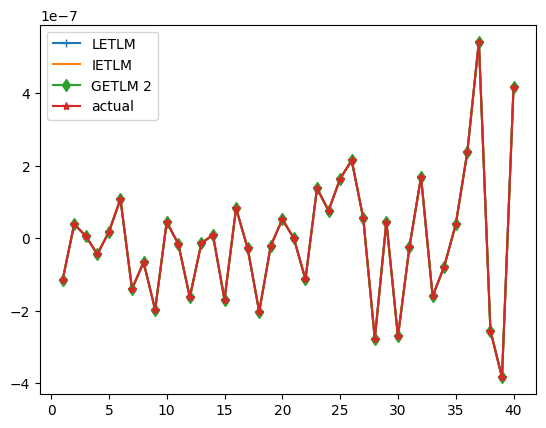

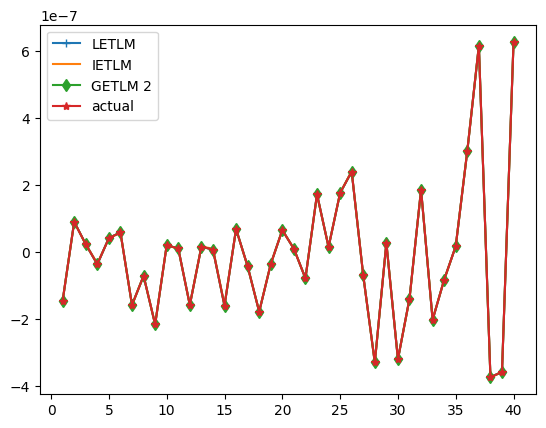

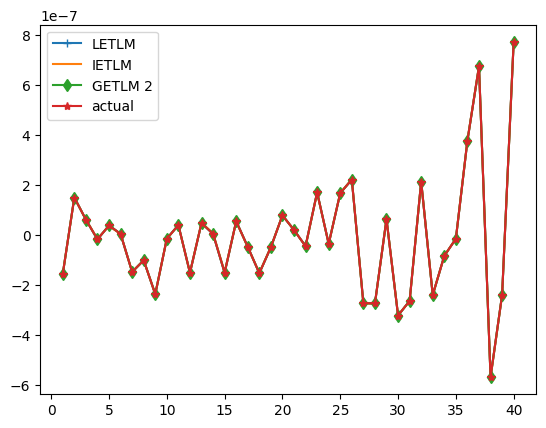

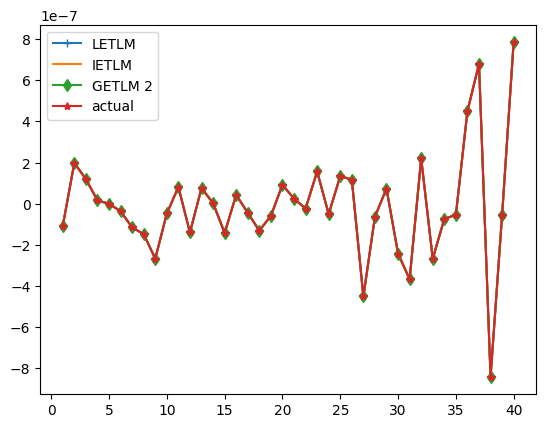

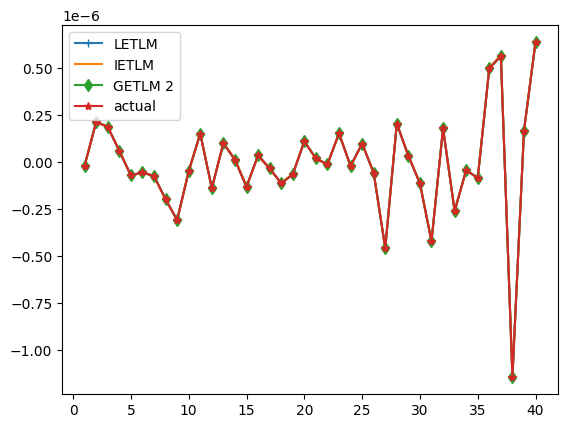

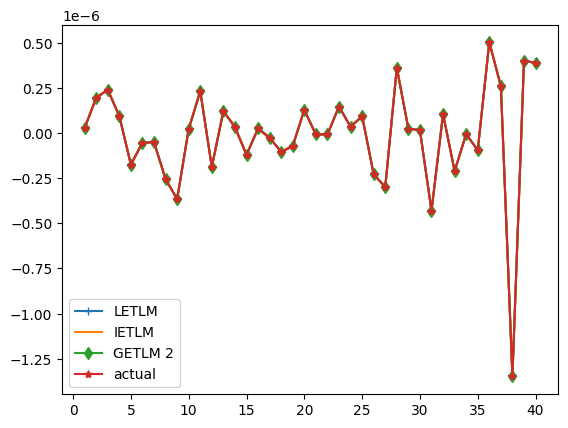

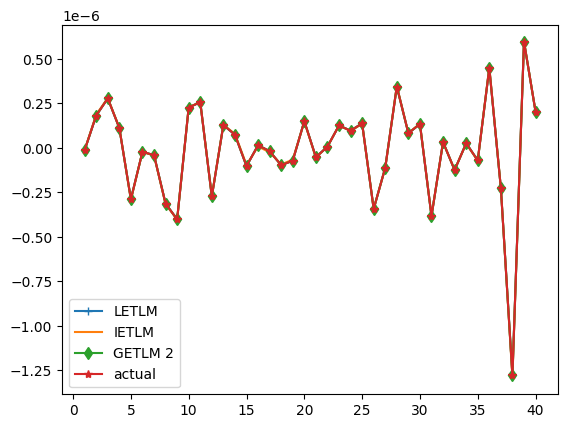

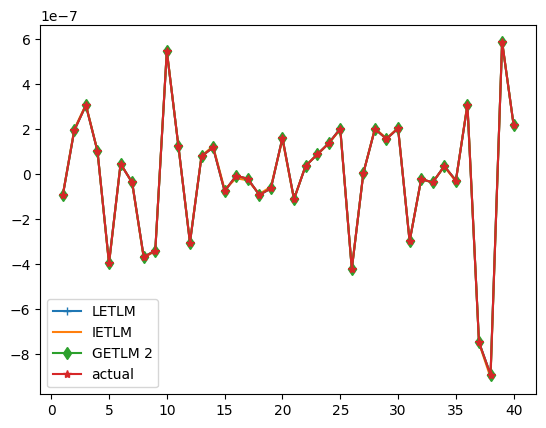

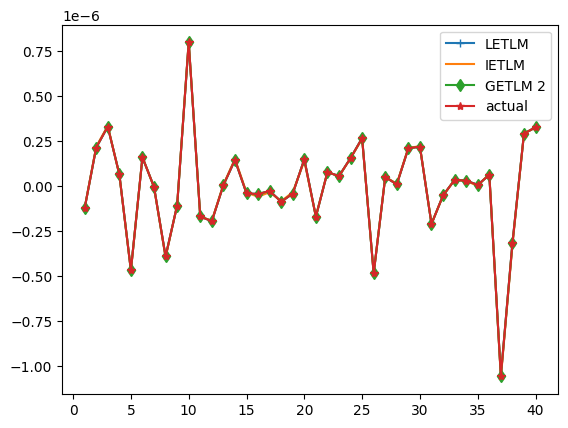

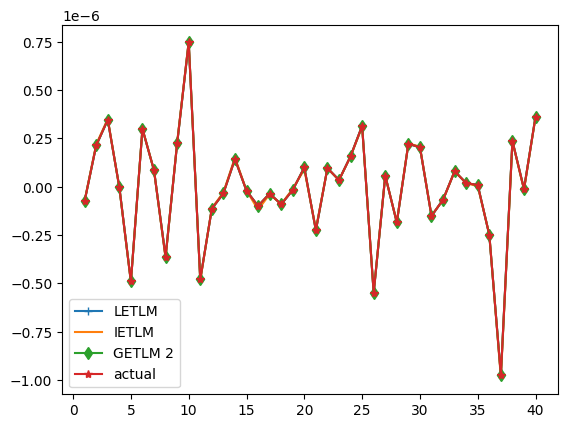

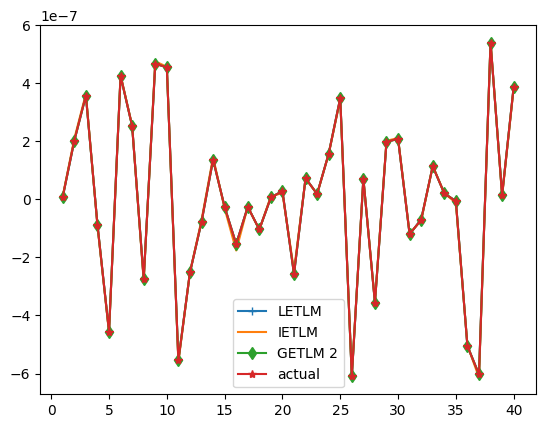

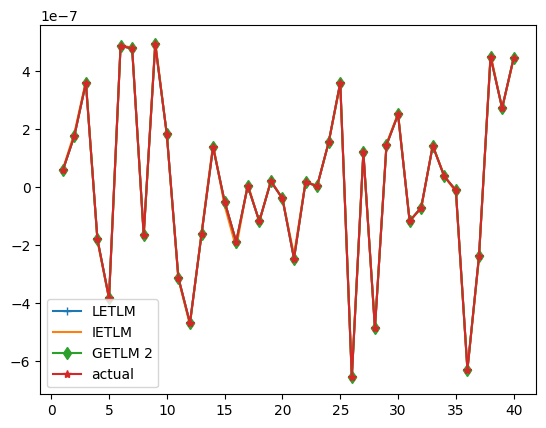

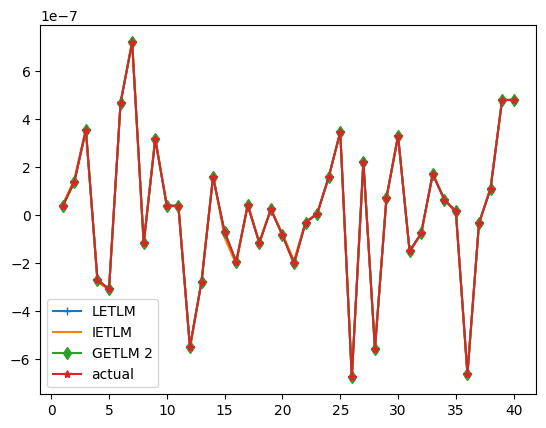

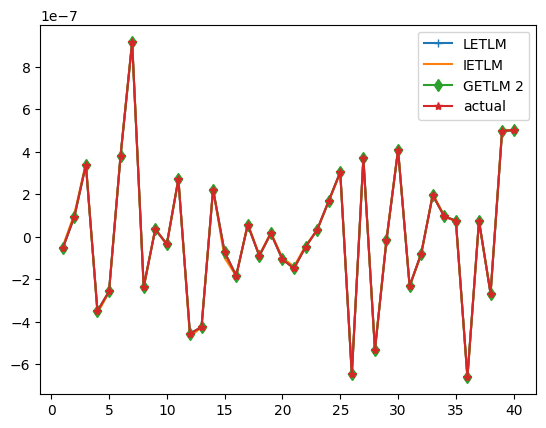

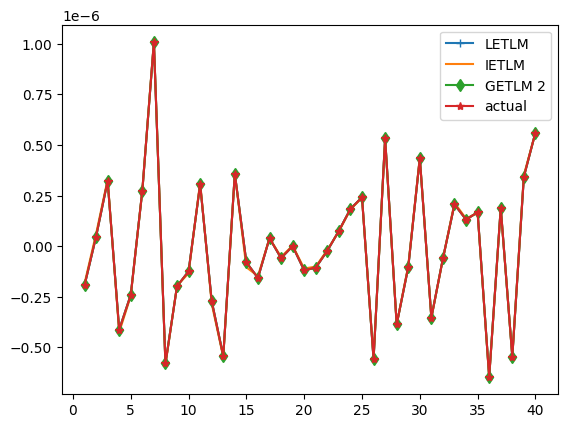

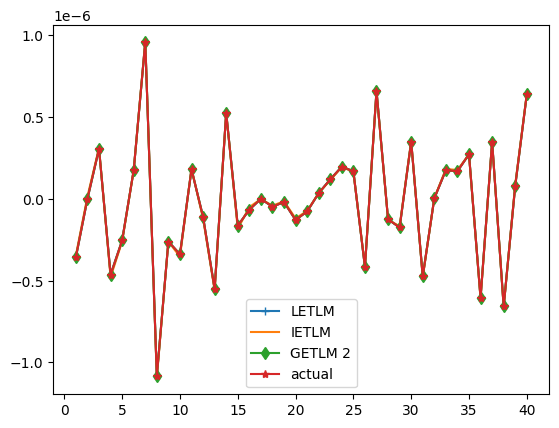

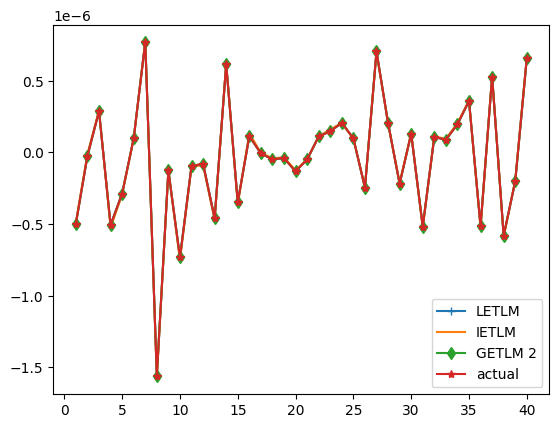

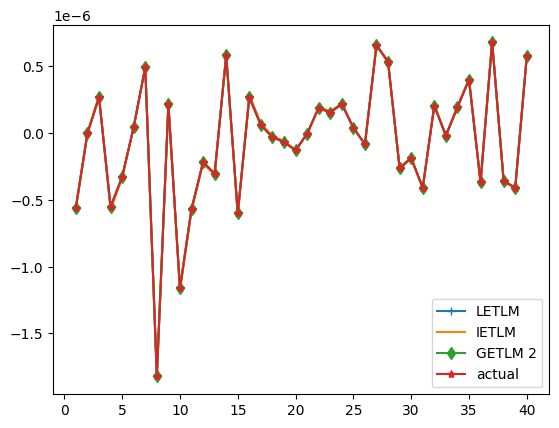

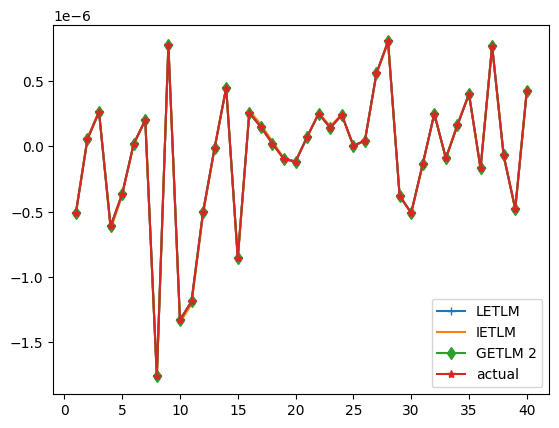

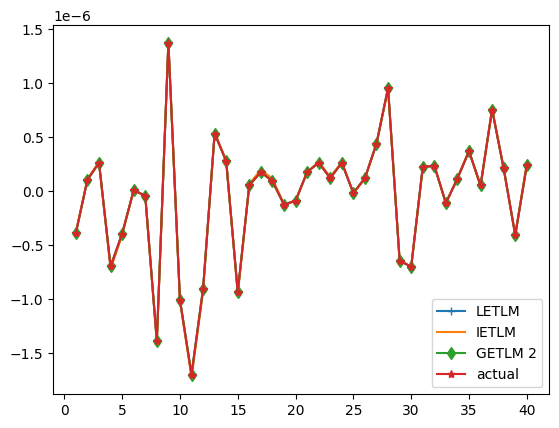

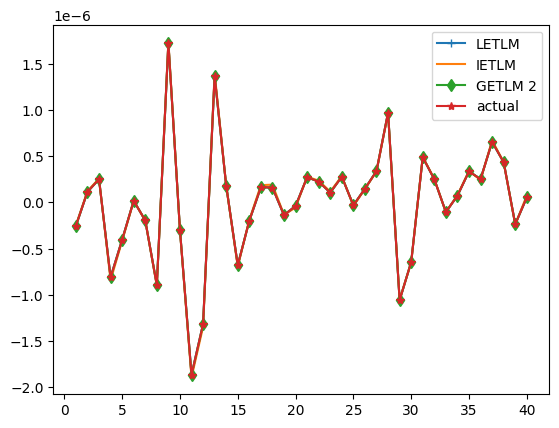

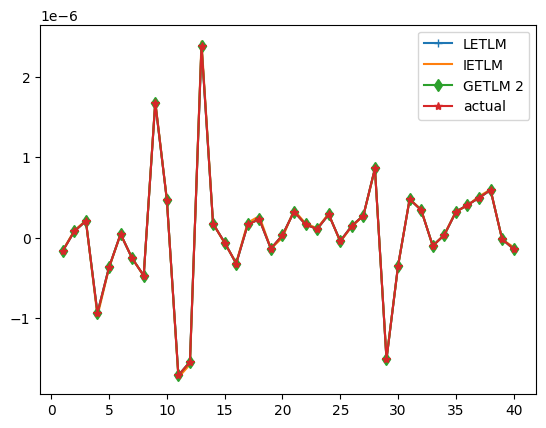

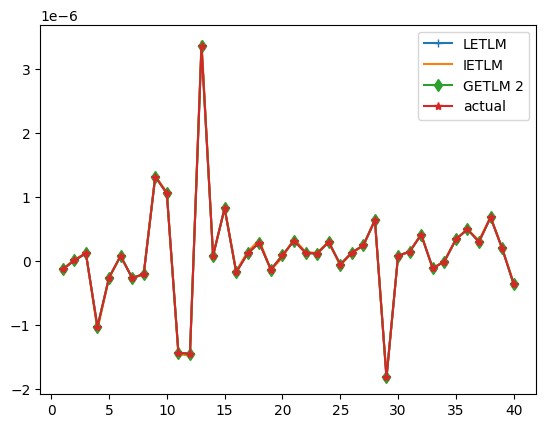

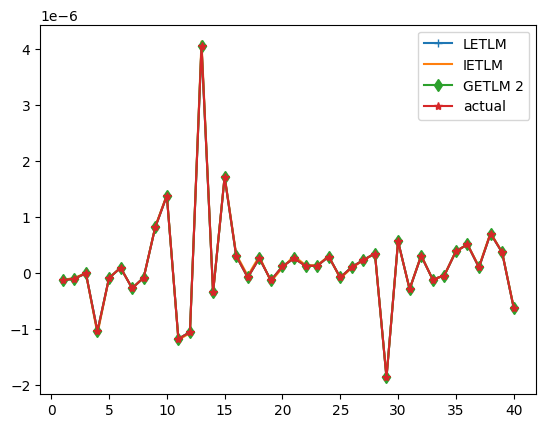

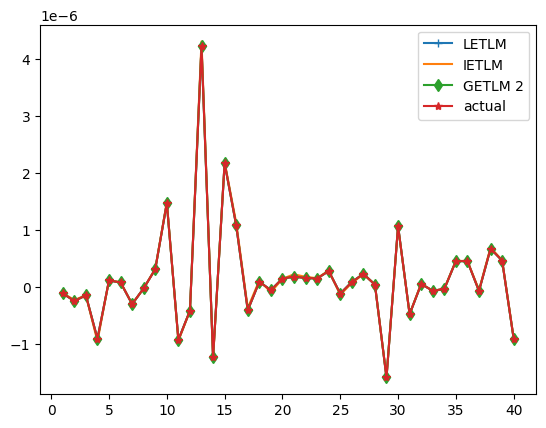

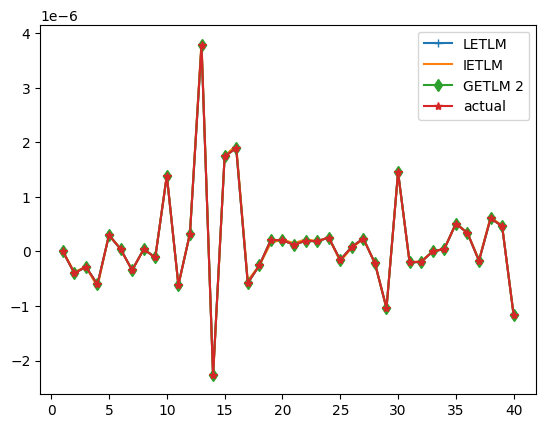

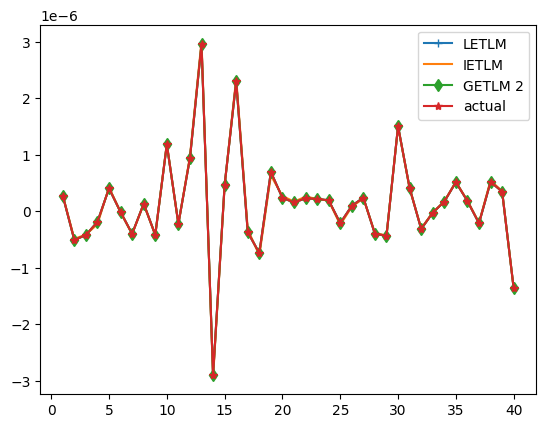

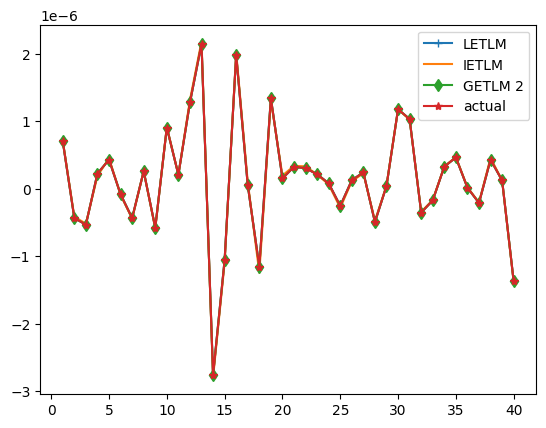

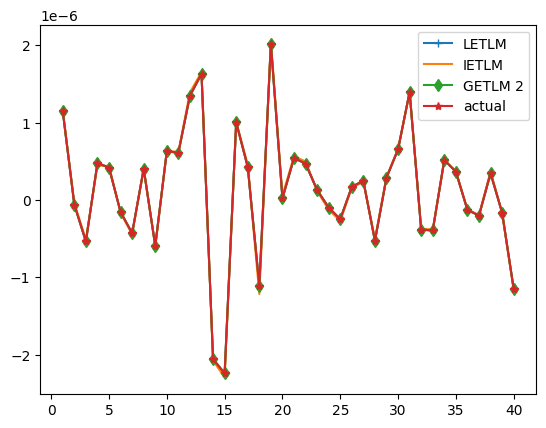

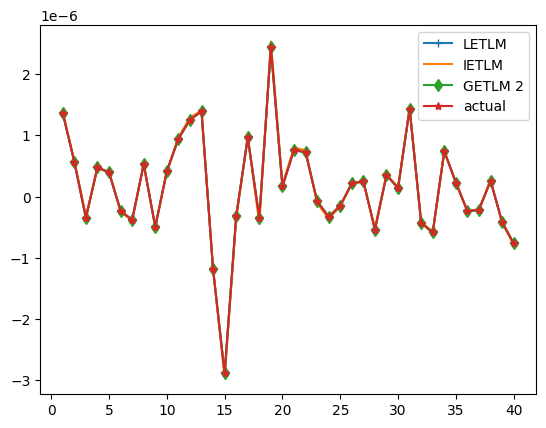

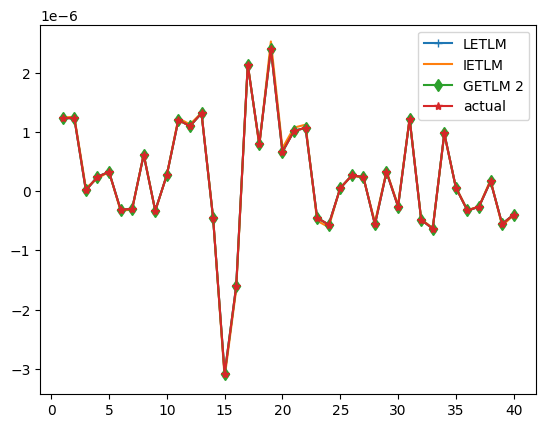

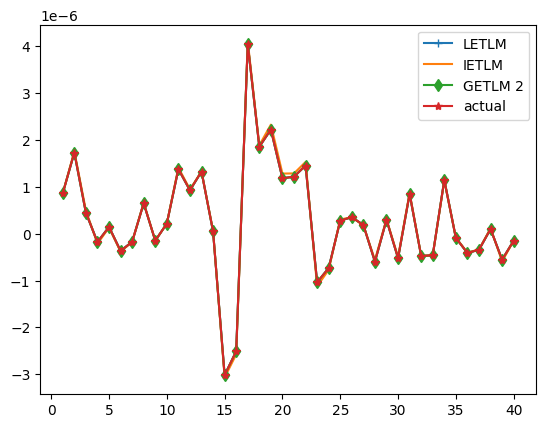

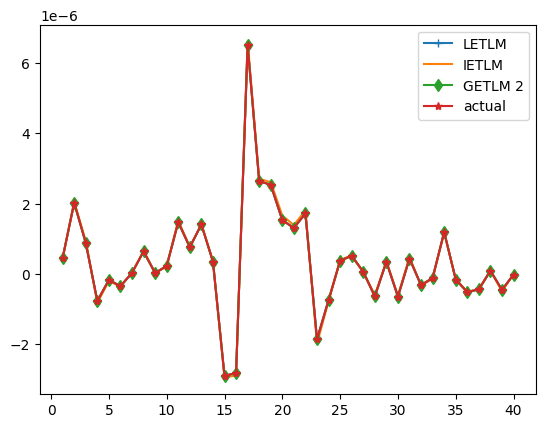

100%|██████████| 1/1 [00:02<00:00,  2.93s/it]
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_67200/491130134.py:32: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  LETLM_mean = torch.mean(torch.tensor(LETLM_TT_result_large), dim = 0)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_67200/491130134.py:33: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  IETLM_mean = torch.mean(torch.tensor(IETLM_TT_result_large), dim = 0)
/var/folders/n6/ghh1_ly93_54z8g_dcc6wj7c0000gp/T/ipykernel_67200/491130134.py:34: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torc

<Figure size 640x480 with 0 Axes>

In [101]:
num_trials = trials
num_step = num_steps

LETLM_TT_result_large = torch.zeros((num_trials, num_step))
# print(LETLM_TT_result_large.shape)
IETLM_TT_result_large = torch.zeros((num_trials, num_step))
GETLM_1_TT_result_large =  torch.zeros((num_trials, num_step))
GETLM_2_TT_result_large =  torch.zeros((num_trials, num_step))
GETLM_3_TT_result_large =  torch.zeros((num_trials, num_step))
GETLM_4_TT_result_large =  torch.zeros((num_trials, num_step))



for i in tqdm(range(num_trials)):
    LETLM_TT_result, IETLM_TT_result, GETLM_1_TT_result, GETLM_2_TT_result = one_trial()


    LETLM_TT_result_large[i,:] = torch.tensor(LETLM_TT_result)
    IETLM_TT_result_large[i,:] = torch.tensor(IETLM_TT_result)
    GETLM_1_TT_result_large[i,:] = torch.tensor(GETLM_1_TT_result)
    
    GETLM_2_TT_result_large[i,:] = torch.tensor(GETLM_2_TT_result)
    # GETLM_3_TT_result_large[i,:] = torch.tensor(GETLM_3_TT_result)
    # GETLM_4_TT_result_large[i,:] = torch.tensor(GETLM_4_TT_result)
    # # print(LETLM_TT_result_large.shape)


# print(torch.tensor(LETLM_TT_result).shape)

# We then take the mean to get the average TLM test error at each time step

LETLM_mean = torch.mean(torch.tensor(LETLM_TT_result_large), dim = 0)
IETLM_mean = torch.mean(torch.tensor(IETLM_TT_result_large), dim = 0)
GETLM_1_mean = torch.mean(torch.tensor(GETLM_1_TT_result_large), dim = 0)
GETLM_2_mean = torch.mean(torch.tensor(GETLM_2_TT_result_large), dim = 0)
GETLM_3_mean = torch.mean(torch.tensor(GETLM_3_TT_result_large), dim = 0)
GETLM_4_mean = torch.mean(torch.tensor(GETLM_4_TT_result_large), dim = 0)

LETLM_sd = torch.std(torch.tensor(LETLM_TT_result_large), dim = 0)
IETLM_sd = torch.std(torch.tensor(IETLM_TT_result_large), dim = 0)
GETLM_1_sd = torch.std(torch.tensor(GETLM_1_TT_result_large), dim = 0)
GETLM_2_sd = torch.std(torch.tensor(GETLM_2_TT_result_large), dim = 0)
GETLM_3_sd = torch.std(torch.tensor(GETLM_3_TT_result_large), dim = 0)
GETLM_4_sd = torch.std(torch.tensor(GETLM_4_TT_result_large), dim = 0)

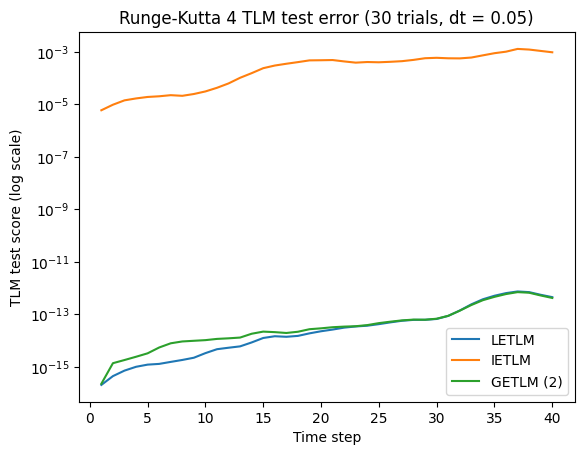

In [102]:
x_axis = np.arange(1, len(LETLM_mean)+1)
plt.plot(x_axis, LETLM_mean, label = 'LETLM')
plt.plot(x_axis, IETLM_mean, label = 'IETLM')
# plt.plot(x_axis, GETLM_1_mean, label = 'GETLM (1)')
plt.plot(x_axis, GETLM_2_mean, label = 'GETLM (2)')
plt.title('Runge-Kutta 4 TLM test error (30 trials, dt = 0.05)')
plt.ylabel('TLM test score (log scale)')
plt.xlabel('Time step')



plt.yscale('log')
plt.legend()
plt.show()


In [103]:
%store -r LETLM_TT_result
%store -r GETLM_2_TT_result

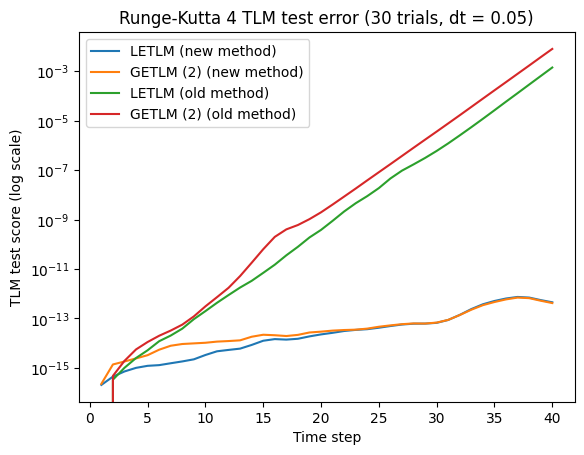

In [104]:
x_axis = np.arange(1, len(LETLM_mean)+1)
plt.plot(x_axis, LETLM_mean, label = 'LETLM (new method)')
plt.plot(x_axis, GETLM_2_mean, label = 'GETLM (2) (new method)')
plt.plot(x_axis, LETLM_TT_result, label = 'LETLM (old method)')
plt.plot(x_axis, GETLM_2_TT_result, label = 'GETLM (2) (old method)')
plt.title('Runge-Kutta 4 TLM test error (30 trials, dt = 0.05)')
plt.ylabel('TLM test score (log scale)')
plt.xlabel('Time step')



plt.yscale('log')
plt.legend()
plt.show()


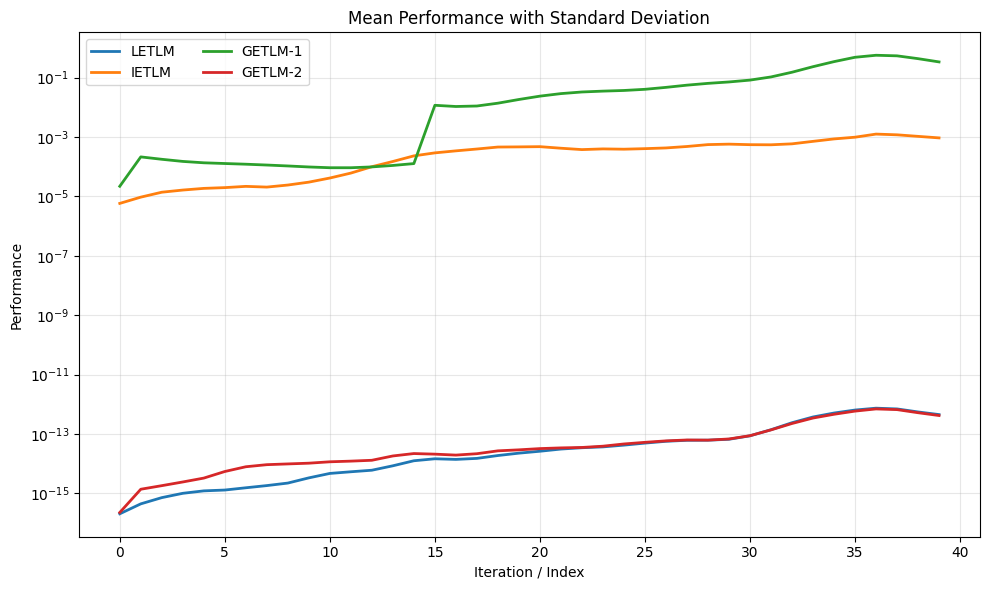

In [105]:
import numpy as np
import matplotlib.pyplot as plt

# Store results in dictionaries
means = {
    'LETLM': LETLM_mean,
    'IETLM': IETLM_mean,
    'GETLM-1': GETLM_1_mean,
    'GETLM-2': GETLM_2_mean,
    # 'GETLM-3': GETLM_3_mean,
    # 'GETLM-4': GETLM_4_mean
}

sds = {
    'LETLM': LETLM_sd,
    'IETLM': IETLM_sd,
    'GETLM-1': GETLM_1_sd,
    'GETLM-2': GETLM_2_sd,
    # 'GETLM-3': GETLM_3_sd,
    # 'GETLM-4': GETLM_4_sd
}

plt.figure(figsize=(10, 6))

for name in means:
    mean = means[name].detach().cpu().numpy()
    sd = sds[name].detach().cpu().numpy()

    x = np.arange(len(mean))

    plt.plot(x, mean, label=name, linewidth=2)
    plt.fill_between(
        x,
        mean - sd,
        mean + sd,
        alpha=0.15
    )
plt.yscale('log')

plt.xlabel('Iteration / Index')
plt.ylabel('Performance')
plt.title('Mean Performance with Standard Deviation')
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

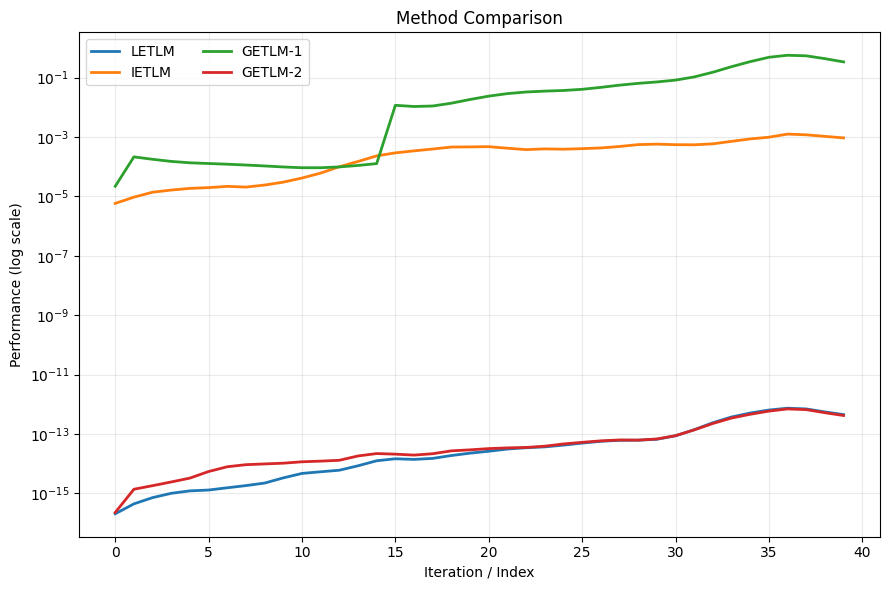

In [106]:
import numpy as np
import matplotlib.pyplot as plt

means = {
    'LETLM': LETLM_mean,
    'IETLM': IETLM_mean,
    'GETLM-1': GETLM_1_mean,
    'GETLM-2': GETLM_2_mean,
    # 'GETLM-3': GETLM_3_mean,
    # 'GETLM-4': GETLM_4_mean
}

sds = {
    'LETLM': LETLM_sd,
    'IETLM': IETLM_sd,
    'GETLM-1': GETLM_1_sd,
    'GETLM-2': GETLM_2_sd,
    # 'GETLM-3': GETLM_3_sd,
    # 'GETLM-4': GETLM_4_sd
}

fig, ax = plt.subplots(figsize=(9, 6))

for name in means:
    mean = means[name].detach().cpu().numpy()
    sd = sds[name].detach().cpu().numpy()
    x = np.arange(len(mean))

    ax.plot(x, mean, linewidth=2, label=name)

    # Only shade where the lower bound is positive
    lower = mean - sd
    upper = mean + sd

    # Cap the lower bound at a small positive value
    lower = np.maximum(lower, 1e-10)

    ax.fill_between(
        x,
        lower,
        upper,
        alpha=0.2
    )

ax.set_yscale('log')

ax.set_xlabel('Iteration / Index')
ax.set_ylabel('Performance (log scale)')
ax.set_title('Method Comparison')
ax.legend(ncol=2)
ax.grid(True, which='both', alpha=0.25)
plt.tight_layout()
plt.show()

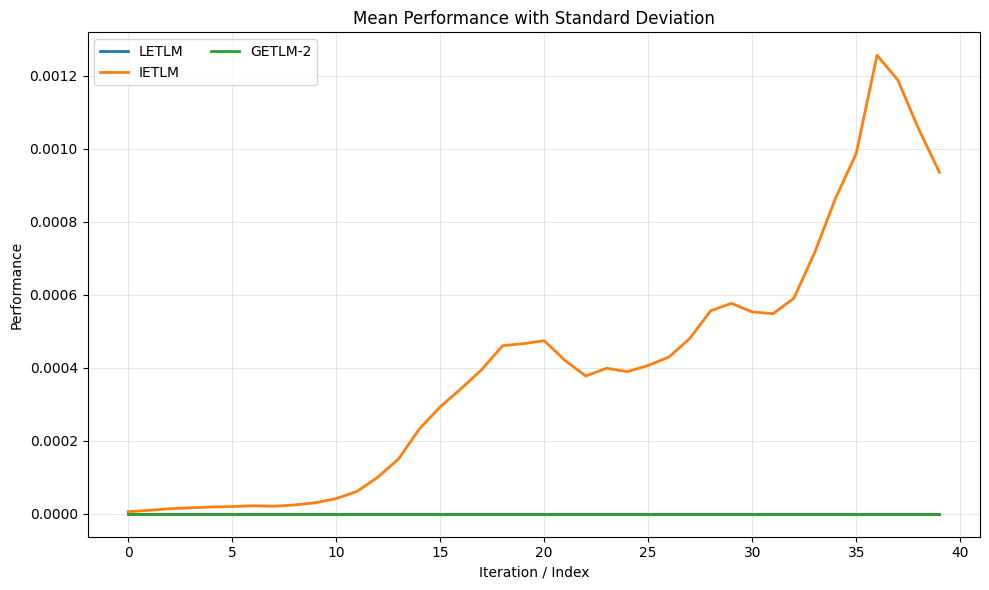

In [107]:
import numpy as np
import matplotlib.pyplot as plt

# Store results in dictionaries
means = {
    'LETLM': LETLM_mean,
    'IETLM': IETLM_mean,
    # 'GETLM-1': GETLM_1_mean,
    'GETLM-2': GETLM_2_mean,
    # 'GETLM-3': GETLM_3_mean,
    # 'GETLM-4': GETLM_4_mean
}

sds = {
    'LETLM': LETLM_sd,
    'IETLM': IETLM_sd,
    # 'GETLM-1': GETLM_1_sd,
    'GETLM-2': GETLM_2_sd,
    # 'GETLM-3': GETLM_3_sd,
    # 'GETLM-4': GETLM_4_sd
}

plt.figure(figsize=(10, 6))

for name in means:
    mean = means[name].detach().cpu().numpy()
    sd = sds[name].detach().cpu().numpy()

    x = np.arange(len(mean))

    plt.plot(x, mean, label=name, linewidth=2)
    plt.fill_between(
        x,
        mean - sd,
        mean + sd,
        alpha=0.15
    )
# plt.yscale('log')

plt.xlabel('Iteration / Index')
plt.ylabel('Performance')
plt.title('Mean Performance with Standard Deviation')
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()